In [1]:
import pandas as pd
import geopandas as gpd
import osmnx as ox

In [2]:
district_stats = pd.read_csv(
    "../data/processed/almaty_district_stats.csv"
)

print(district_stats.shape)
display(district_stats.head())

(8, 9)


,district,housing_completed_m2,housing_investment_mln_kzt,population_2026,avg_salary_kzt,active_sme_2026,sme_per_1000_residents,housing_m2_per_1000_residents,housing_investment_per_capita_kzt
0,Алмалинский,153516,44300,275160,588210,59754,217.160925,557.915395,160997.237971
1,Алатауский,634455,113365,413952,461788,53627,129.548837,1532.677702,273860.254329
2,Ауэзовский,18424,5674,362597,419917,52459,144.675770,50.811231,15648.226544
3,Бостандыкский,254271,78539,355956,716798,65143,183.008574,714.332670,220642.438953
4,Жетысуский,151252,48668,199035,452573,34182,171.738639,759.926646,244519.808074


# Получаем административные границы

In [1]:
import geopandas as gpd

url = (
    "https://services.arcgis.com/HOo89W8RWwrXP286/arcgis/rest/"
    "services/Almaty_Districts/FeatureServer/0/query"
    "?where=1%3D1&outFields=%2A&returnGeometry=true"
    "&outSR=4326&f=geojson"
)

districts = gpd.read_file(url)

In [2]:
print(districts.shape)
print(districts.crs)
print(districts[["NAME", "geometry"]])
print(districts.geometry.is_valid.value_counts())
print(districts["NAME"].is_unique)

(8, 10)
EPSG:4326
            NAME                                           geometry
0     Ауэзовский  POLYGON ((76.82262 43.22369, 76.82172 43.2252,...
1     Алатауский  POLYGON ((76.85615 43.33455, 76.85615 43.33455...
2      Медеуский  MULTIPOLYGON (((77.14701 43.17817, 77.145 43.1...
3  Наурызбайский  POLYGON ((76.7719 43.21574, 76.77194 43.21799,...
4     Жетысуский  POLYGON ((76.96372 43.37982, 76.96375 43.37963...
5    Алмалинский  POLYGON ((76.87088 43.2332, 76.87008 43.23381,...
6    Турксибский  POLYGON ((77.02587 43.3196, 77.02513 43.31995,...
7  Бостандыкский  POLYGON ((76.99488 43.05108, 76.99487 43.04947...
True    8
Name: count, dtype: int64
True


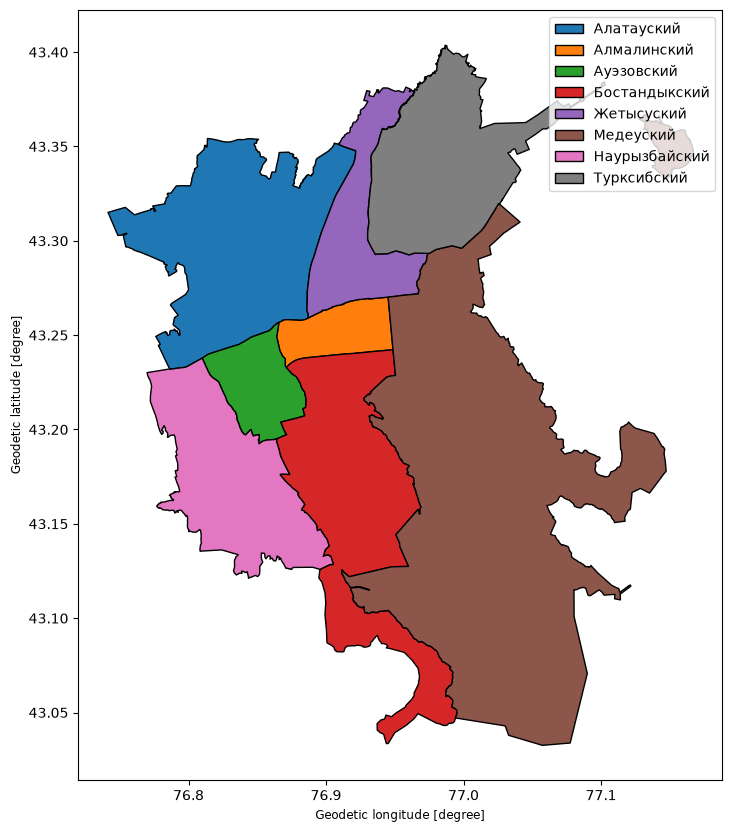

In [3]:
ax = districts.plot(
    column="NAME",
    figsize=(12, 10),
    edgecolor="black",
    legend=True
)

In [4]:
districts.to_parquet(
    "../data/processed/almaty_districts.parquet"
)

In [5]:
import pandas as pd

stats = pd.read_csv(
    "../data/processed/almaty_district_stats.csv"
)

print(stats.columns.tolist())
print(districts.columns.tolist())

['district', 'housing_completed_m2', 'housing_investment_mln_kzt', 'population_2026', 'avg_salary_kzt', 'active_sme_2026', 'sme_per_1000_residents', 'housing_m2_per_1000_residents', 'housing_investment_per_capita_kzt']
['OBJECTID', 'NAME', 'RAION', 'GlobalID', 'Population_est', 'Schools_capacity', 'Students_to_population', 'Shape__Area', 'Shape__Length', 'geometry']


# Соединение statgov и district 

In [6]:
print(districts.shape)
print(districts.crs)
print(districts[["NAME", "geometry"]])
print(districts.geometry.is_valid.value_counts())
print(districts["NAME"].is_unique)

(8, 10)
EPSG:4326
            NAME                                           geometry
0     Ауэзовский  POLYGON ((76.82262 43.22369, 76.82172 43.2252,...
1     Алатауский  POLYGON ((76.85615 43.33455, 76.85615 43.33455...
2      Медеуский  MULTIPOLYGON (((77.14701 43.17817, 77.145 43.1...
3  Наурызбайский  POLYGON ((76.7719 43.21574, 76.77194 43.21799,...
4     Жетысуский  POLYGON ((76.96372 43.37982, 76.96375 43.37963...
5    Алмалинский  POLYGON ((76.87088 43.2332, 76.87008 43.23381,...
6    Турксибский  POLYGON ((77.02587 43.3196, 77.02513 43.31995,...
7  Бостандыкский  POLYGON ((76.99488 43.05108, 76.99487 43.04947...
True    8
Name: count, dtype: int64
True


In [7]:
districts.head()

,OBJECTID,NAME,RAION,GlobalID,Population_est,Schools_capacity,Students_to_population,Shape__Area,Shape__Length,geometry
0,1,Ауэзовский,312,db4a4813-efd1-471d-893b-3f2507c46d0e,216162,53708,248,2.954654e+07,25014.992782,"POLYGON ((76.82262 43.22369, 76.82172 43.2252,..."
1,2,Алатауский,321,78d6ecb8-2019-4749-97b2-804f490cbe32,182493,51706,283,1.307575e+08,72807.531267,"POLYGON ((76.85615 43.33455, 76.85615 43.33455..."
2,3,Медеуский,315,4961c1d5-0d34-47fc-9771-73b2da36b5a5,172300,30419,177,3.421883e+08,160289.173415,"MULTIPOLYGON (((77.14701 43.17817, 77.145 43.1..."
3,4,Наурызбайский,322,802307fb-e1a6-427d-8d89-48b0f92d4050,164413,19066,116,8.763143e+07,58380.265837,"POLYGON ((76.7719 43.21574, 76.77194 43.21799,..."
4,5,Жетысуский,314,db3f1d4c-0d4b-49ad-9830-0e2c1a20d246,114473,28551,249,4.923601e+07,51339.717717,"POLYGON ((76.96372 43.37982, 76.96375 43.37963..."


In [8]:
districts['NAME'] = districts['NAME'].str.strip()

df_merged = pd.merge(
    districts,
    stats,
    how='left',
    left_on='NAME',
    right_on='district',
    validate='one_to_one',
    indicator=True
)

In [10]:
print(df_merged.shape)
print(df_merged["_merge"].value_counts())
print(df_merged[["NAME", "district", "_merge"]])
print(df_merged.geometry.is_valid.all())

print(type(df_merged))
print(df_merged.crs)

(8, 20)
_merge
both          8
left_only     0
right_only    0
Name: count, dtype: int64
            NAME       district _merge
0     Ауэзовский     Ауэзовский   both
1     Алатауский     Алатауский   both
2      Медеуский      Медеуский   both
3  Наурызбайский  Наурызбайский   both
4     Жетысуский     Жетысуский   both
5    Алмалинский    Алмалинский   both
6    Турксибский    Турксибский   both
7  Бостандыкский  Бостандыкский   both
True
<class 'geopandas.geodataframe.GeoDataFrame'>
EPSG:4326


# Spatial join

In [ ]:
# df_merged = df_merged.drop(columns=["_merge"])

df_merged.to_parquet(
    "../data/processed/almaty_districts_with_stats.parquet"
)


AttributeError: 'DataFrame' object has no attribute 'crs'

In [15]:
import geopandas as gpd

candidates = gpd.read_parquet(
    "../data/processed/almaty_features.parquet"
)

print(candidates.shape)
print(candidates.crs)
print(candidates.geometry.geom_type.value_counts())
print(candidates.head())

(2822, 14)
{"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "WGS 84 / UTM zone 43N", "base_crs": {"type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longitude", "abb

In [16]:
districts_projected = districts.to_crs('EPSG:32643')

print(districts_projected.crs.to_epsg())
print(candidates.crs == districts_projected.crs)


32643
True


In [17]:
joined = gpd.sjoin(
    candidates,
    districts_projected,
    how="left",
    predicate="within"
)

print("Исходных точек:", len(candidates))
print("Строк после join:", len(joined))
print("Без района:", joined["NAME"].isna().sum())
print("Дублирующихся индексов:", joined.index.duplicated().sum())

Исходных точек: 2822
Строк после join: 2822
Без района: 14
Дублирующихся индексов: 0


In [19]:
unmatched = joined[joined['NAME'].isna()].copy()
print(unmatched.shape)

(14, 24)


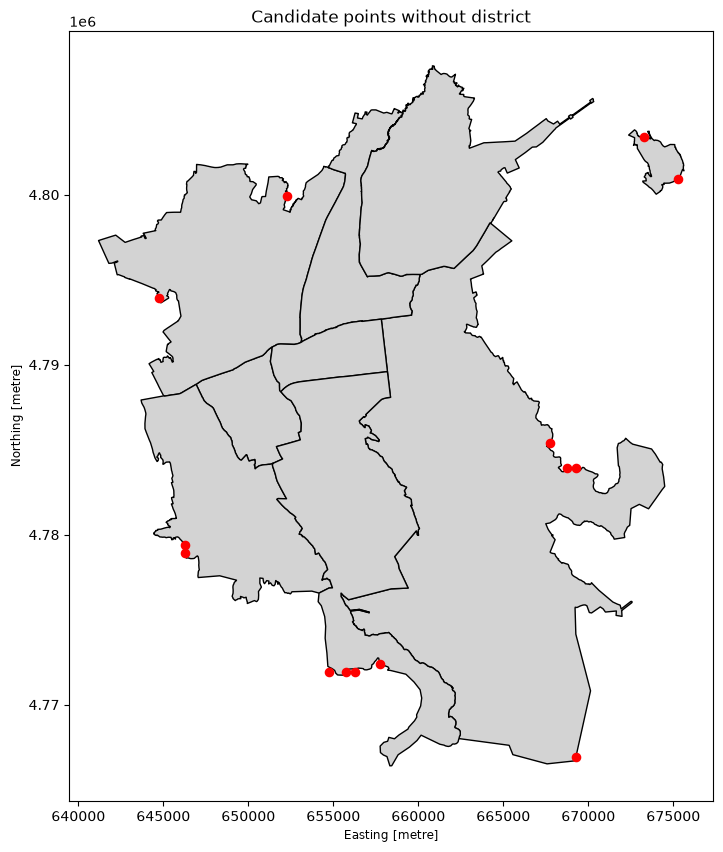

In [21]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12,10))

districts_projected.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black"
)

unmatched.plot(
    ax=ax,
    color="red",
    markersize=35
)

plt.title("Candidate points without district")
plt.show()

In [22]:
distances = unmatched.geometry.apply(
    lambda point: districts_projected.geometry.distance(point).min()
)

print(distances.describe())
print(distances)

count     14.000000
mean      56.861704
std       85.229399
min        0.033575
25%        4.609767
50%       22.956508
75%       45.935908
max      273.785675
Name: geometry, dtype: float64
636       1.174777
855      11.472831
856       0.033575
1893     44.521041
2252    273.785675
2418     33.075664
2501    214.863149
2751     46.407530
4437     13.042103
4600    108.960743
4649      2.322079
4683      0.491676
5386     15.592097
5713     30.320918
Name: geometry, dtype: float64


In [23]:
nearest = gpd.sjoin_nearest(
    unmatched[["geometry"]],
    districts_projected[["NAME", "geometry"]],
    how="left",
    distance_col="distance_m"
)

print(
    nearest[["NAME", "distance_m"]]
    .sort_values("distance_m", ascending=False)
)

               NAME  distance_m
2252  Бостандыкский  273.785675
2501  Бостандыкский  214.863149
4600      Медеуский  108.960743
2751  Бостандыкский   46.407530
1893     Алатауский   44.521041
2418  Бостандыкский   33.075664
5713      Медеуский   30.320918
5386      Медеуский   15.592097
4437      Медеуский   13.042103
855   Наурызбайский   11.472831
4649      Медеуский    2.322079
636      Алатауский    1.174777
4683      Медеуский    0.491676
856   Наурызбайский    0.033575


In [24]:
unmatched_diagnostics = nearest[
    ["NAME", "distance_m", "geometry"]
].copy()

unmatched_diagnostics = unmatched_diagnostics.rename(
    columns={"NAME": "nearest_district"}
)

unmatched_diagnostics.to_parquet(
    "../data/processed/unmatched_candidates.parquet"
)

In [25]:
print(joined.isna().sum()[joined.isna().sum() > 0])

index_right               14
OBJECTID                  14
NAME                      14
RAION                     14
GlobalID                  14
Population_est            14
Schools_capacity          14
Students_to_population    14
Shape__Area               14
Shape__Length             14
dtype: int64


In [26]:
print(joined.columns.tolist())

['geometry', 'cafes_500m', 'cafes_300m', 'cafes_1000m', 'bus_stops_500m', 'residential_buildings_500m', 'houses_500m', 'apartments_500m', 'residential_unknown_500m', 'office_polygons_500m', 'offices_pois_500m', 'universities_500m', 'colleges_500m', 'schools_500m', 'index_right', 'OBJECTID', 'NAME', 'RAION', 'GlobalID', 'Population_est', 'Schools_capacity', 'Students_to_population', 'Shape__Area', 'Shape__Length']


In [27]:
stat_columns = [
    "population_2026",
    "avg_salary_kzt",
    "active_sme_2026",
    "sme_per_1000_residents"
]

print(joined[stat_columns].isna().sum())

KeyError: "None of [Index(['population_2026', 'avg_salary_kzt', 'active_sme_2026',\n       'sme_per_1000_residents'],\n      dtype='str')] are in the [columns]"

In [28]:
print(df_merged.columns.tolist())
print(df_merged.shape)

['OBJECTID', 'NAME', 'RAION', 'GlobalID', 'Population_est', 'Schools_capacity', 'Students_to_population', 'Shape__Area', 'Shape__Length', 'geometry', 'district', 'housing_completed_m2', 'housing_investment_mln_kzt', 'population_2026', 'avg_salary_kzt', 'active_sme_2026', 'sme_per_1000_residents', 'housing_m2_per_1000_residents', 'housing_investment_per_capita_kzt']
(8, 19)


In [29]:
districts_projected = df_merged.to_crs(candidates.crs)

In [30]:
joined = gpd.sjoin(
    candidates,
    districts_projected,
    how="left",
    predicate="within"
)

print(joined.shape)

print(
    joined[
        ["NAME", "population_2026",
         "avg_salary_kzt", "sme_per_1000_residents"]
    ].head()
)

print("Без района:", joined["NAME"].isna().sum())
print("Дубликаты:", joined.index.duplicated().sum())

(2822, 33)
           NAME  population_2026  avg_salary_kzt  sme_per_1000_residents
143  Алатауский         413952.0        461788.0              129.548837
144  Алатауский         413952.0        461788.0              129.548837
145  Алатауский         413952.0        461788.0              129.548837
225  Алатауский         413952.0        461788.0              129.548837
226  Алатауский         413952.0        461788.0              129.548837
Без района: 14
Дубликаты: 0


# Удаление тех столбцов

In [31]:
final_df = joined.copy()

In [32]:
technical_columns = [
    "index_right",
    "OBJECTID",
    "GlobalID",
    "Shape__Area",
    "Shape__Length"
]

final_df = final_df.drop(columns=technical_columns)

In [33]:
print(final_df.shape)
print(final_df.isna().sum()[final_df.isna().sum() > 0])
print(final_df.crs.to_epsg())

(2822, 28)
NAME                                 14
RAION                                14
Population_est                       14
Schools_capacity                     14
Students_to_population               14
district                             14
housing_completed_m2                 14
housing_investment_mln_kzt           14
population_2026                      14
avg_salary_kzt                       14
active_sme_2026                      14
sme_per_1000_residents               14
housing_m2_per_1000_residents        14
housing_investment_per_capita_kzt    14
dtype: int64
32643


In [34]:
final_df.to_parquet(
    "../data/processed/almaty_enriched_candidates.parquet"
)

In [35]:
check = gpd.read_parquet(
    "../data/processed/almaty_enriched_candidates.parquet"
)

assert len(check) == 2822
assert check.crs.to_epsg() == 32643
assert check["NAME"].isna().sum() == 14

print("Dataset saved successfully!")

Dataset saved successfully!
